# ML and Deep Learning Models
Compare classical ML algorithms with a PyTorch neural network on the same split.

In [1]:
import sys; sys.path.append('..')
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
from src.data import load_data
from src.ml_models import get_models, compare_models
from src.deep_learning import TorchClassifier
sns.set_theme()

## 1. Data and split

In [2]:
df = load_data()
X, y = df.drop(columns='target'), df['target']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

## 2. Classical machine learning (5-fold CV)
Logistic regression, k-NN, SVM, decision tree, random forest, gradient boosting.

In [3]:
models = get_models()
results = compare_models(models, X_train, y_train)
results

,model,mean,std
0,logreg,0.980220,0.012815
1,svm,0.971429,0.017855
2,knn,0.967033,0.020850
3,random_forest,0.960440,0.019160
4,gradient_boosting,0.956044,0.013900
5,decision_tree,0.909890,0.018906


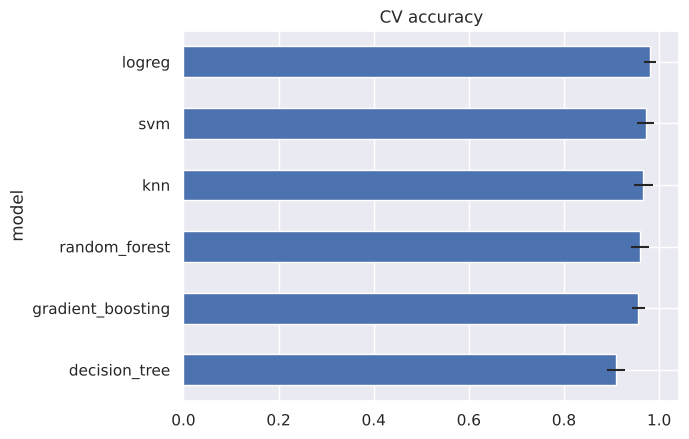

In [4]:
results.sort_values('mean').plot.barh(x='model', y='mean', xerr='std', legend=False, title='CV accuracy');

## 3. Deep learning (PyTorch MLP)

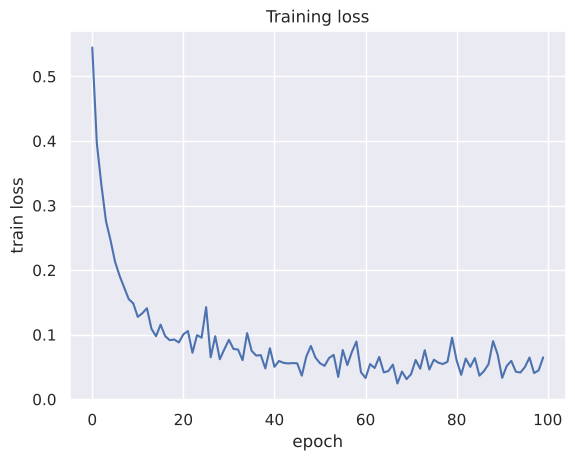

In [5]:
net = TorchClassifier(hidden=(64, 32), epochs=100).fit(X_train, y_train)
plt.plot(net.history); plt.xlabel('epoch'); plt.ylabel('train loss'); plt.title('Training loss');

## 4. Test-set comparison

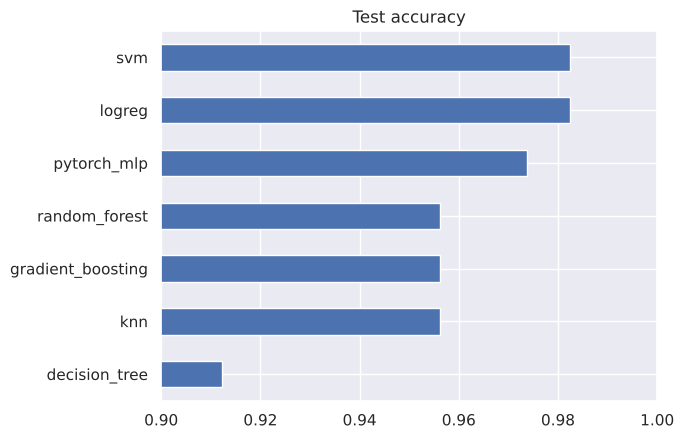

In [6]:
test_scores = {}
for name, m in models.items():
    test_scores[name] = accuracy_score(y_test, m.fit(X_train, y_train).predict(X_test))
test_scores['pytorch_mlp'] = accuracy_score(y_test, net.predict(X_test))
import pandas as pd
pd.Series(test_scores).sort_values().plot.barh(title='Test accuracy', xlim=(0.9, 1.0));

              precision    recall  f1-score   support

           0       0.98      0.95      0.96        42
           1       0.97      0.99      0.98        72

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114



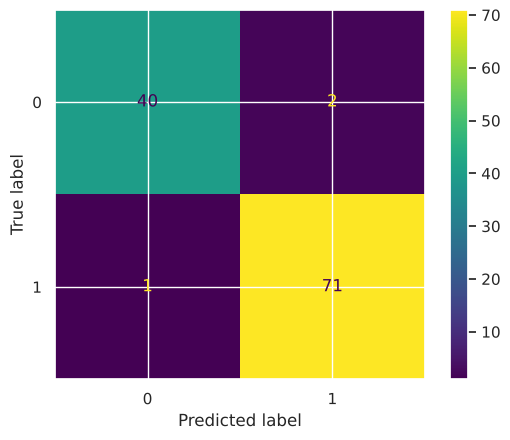

In [7]:
pred = net.predict(X_test)
print(classification_report(y_test, pred))
ConfusionMatrixDisplay.from_predictions(y_test, pred);

## Next steps
- Tune hyperparameters (GridSearchCV / Optuna)
- Try CNNs/RNNs on image or sequence data
- Replace the dataset with your own